# Controlled 3-state measure-valued 2BSDE: time-block implementation
# 30 time steps, 3 blocks, with boundary penalty and derivative consistency loss, no gradient loss penalty

We use the existing `two_bsde` package and the same problem as the original notebook.

Run this notebook beside your `two_bsde` folder. The imports below use the supplied A–I filenames; the model module should be named `F_2BSDE_structure.py` (without the upload suffix `(1)`).

We test the time-block implementation on

$$
\Theta\in\{-1,0,1\},
\qquad
dY_t=u_t\Theta\,dt+dW_t.
$$

The posterior satisfies

$$
d\pi_t^i
=
u_t\pi_t^i(\theta_i-\bar\theta_t)\,dI_t,
\qquad
\bar\theta_t=\sum_i\pi_t^i\theta_i.
$$

Thus the control genuinely changes the posterior diffusion.

Define

$$
b_i(\pi)=\pi_i(\theta_i-\bar\theta),
\qquad
S(\pi)=\sum_i b_i(\pi)^2,
$$

and choose

$$
k(\pi,u)
=
\frac12 u^2 S(\pi)
+
\frac{\lambda}{2}(u-1)^2,
$$

with terminal cost

$$
g(\pi)
=
\frac12(1-\|\pi\|^2).
$$

For

$$
V(t,y,\pi)=\frac12(1-\|\pi\|^2),
$$

we have $D^2_{\pi\pi}V=-I$, so the KS second-order term is

$$
-\frac12u^2S(\pi),
$$

which cancels the first term in the running cost. Hence the HJB reduces to

$$
\min_{u\in[-1,1]}
\frac{\lambda}{2}(u-1)^2=0.
$$

Therefore the exact solution is

$$
\boxed{
V(t,y,\pi)=\frac12(1-\|\pi\|^2),
\qquad
u^*(t,y,\pi)\equiv1.
}
$$

We compare the learned initial value with $V_0=0.3125$ and the learned Hamiltonian controls with $u^*\equiv1$.


In [1]:
from pathlib import Path
import math
import sys

import numpy as np
import torch
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from two_bsde.config import ModelConfig, HamiltonianConfig, TrainingConfig
from two_bsde.problem import BayesianControlProblem
from two_bsde.geometry import make_simplex_tangent_basis, SimplexGeometry
from two_bsde.hamiltonian import HamiltonianOptimizer
from two_bsde.twoBsdeStructure import GeometricTimeBlockAdaptive2BSDE
from two_bsde.dynamics import split_state, posterior_mean_sensor_and_diffusion
from two_bsde.training import train_time_blocks
from two_bsde.evaluation import evaluate_time_blocks

DTYPE = torch.float64
DEVICE = torch.device("cpu")

torch.manual_seed(42)
np.random.seed(42)


In [2]:
config = ModelConfig(
    horizon=1.0,
    hidden_dim=1,
    observation_dim=1,
    control_dim=1,
    num_hidden_states=3,
    num_time_steps=30,
    network_width=64,
    network_depth=5,
    value_initial_guess=0.01,
    gamma_initial_scale=0.01,
)

ham_config = HamiltonianConfig(
    num_starts=12,
    num_steps=30,
    learning_rate=5e-2,
)

training_config = TrainingConfig(
    epochs=1500,
    batch_size=128,
    learning_rate=1e-4,
    gradient_clip=10.0,
    value_loss_weight=1.0,
    gradient_loss_weight=0.0,
)

basis = make_simplex_tangent_basis(
    config.num_hidden_states,
    dtype=DTYPE,
    device=DEVICE,
)

geometry = SimplexGeometry(
    observation_dim=config.observation_dim,
    basis=basis,
)

print("state_dim =", config.state_dim)
print("tangent_dim =", config.tangent_dim)

state_dim = 4
tangent_dim = 2


## Concrete problem

In [3]:
class ControlledThreeStateProblem(BayesianControlProblem):
    def __init__(self, config, lam=1.0):
        super().__init__(config)
        self.lam = float(lam)

        self.theta = torch.tensor([-1.0, 0.0, 1.0], dtype=DTYPE, device=DEVICE)
        self.x_support = self.theta[:, None].clone()

        self.initial_observation = torch.tensor([0.0], dtype=DTYPE, device=DEVICE)
        self.initial_posterior = torch.tensor([0.25, 0.50, 0.25], dtype=DTYPE, device=DEVICE)

        self.control_low = torch.tensor([-1.0], dtype=DTYPE, device=DEVICE)
        self.control_high = torch.tensor([1.0], dtype=DTYPE, device=DEVICE)

        # Required by the problem interface; the time-block model
        # chooses its auxiliary controls during the forward pass.
        self.auxiliary_control_path = torch.zeros(
            config.num_time_steps,
            config.control_dim,
            dtype=DTYPE,
            device=DEVICE,
        )

        self.validate(config)

    def sensor(self, control, observation):
        lead_shape = control.shape[:-1]
        theta = self.theta.reshape(
            *([1] * len(lead_shape)),
            self.config.num_hidden_states,
            1,
        )
        return control.unsqueeze(-2) * theta

    def running_cost(self, state, control, time=None):
        p = state[..., self.config.observation_dim:]
        theta_bar = (p * self.theta).sum(dim=-1,keepdim=True)
        b = p * (self.theta - theta_bar)
        u = control[..., 0]

        cancellation_term = (
            0.5 * u.square() * b.square().sum(dim=-1)
        )

        force_u_to_one = (
            0.5 * self.lam * (u - 1.0).square()
        )

        return cancellation_term + force_u_to_one

    def terminal_cost(self, state):
        _, p = split_state(state, self.config)
        return 0.5 * (1.0 - p.square().sum(dim=-1))


problem = ControlledThreeStateProblem(config)
S0 = torch.cat(
    (problem.initial_observation, problem.initial_posterior)
)

print("S0 =", S0)
print("theta =", problem.theta)
print("auxiliary control =", problem.auxiliary_control_path.squeeze(-1))


S0 = tensor([0.0000, 0.2500, 0.5000, 0.2500], dtype=torch.float64)
theta = tensor([-1.,  0.,  1.], dtype=torch.float64)
auxiliary control = tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0.], dtype=torch.float64)


## Analytic solution

In [4]:
def exact_value(state):
    p = state[..., 1:]
    return 0.5 * (1.0 - p.square().sum(dim=-1))


def exact_gradient(state):
    ambient = torch.zeros_like(state)
    ambient[..., 1:] = -state[..., 1:]
    return geometry.project_gradient(ambient)


def exact_hessian(state):
    shape = state.shape[:-1] + (
        config.state_dim,
        config.state_dim,
    )
    gamma = torch.zeros(
        shape,
        dtype=state.dtype,
        device=state.device,
    )
    gamma[..., 1:, 1:] = -geometry.projector
    return gamma


def exact_control(state):
    return torch.ones(
        *state.shape[:-1],
        1,
        dtype=state.dtype,
        device=state.device,
    )


V0_exact = exact_value(S0)
u0_exact = exact_control(S0)

print("exact V0 =", V0_exact.item())
print("exact u0* =", u0_exact)


exact V0 = 0.3125
exact u0* = tensor([1.], dtype=torch.float64)


## Verify the analytic HJB

In [5]:
def analytic_hjb_expression(state, control):
    _, B = posterior_mean_sensor_and_diffusion(
        state,
        control,
        problem=problem,
        config=config,
        geometry=geometry,
    )

    running = problem.running_cost(
        state,
        control,
    )

    second_order = (
        -0.5
        * B.square().sum(dim=(-2, -1))
    )

    return running + second_order


test_states = torch.tensor(
    [
        [0.0, 0.20, 0.50, 0.30],
        [0.4, 0.70, 0.20, 0.10],
        [-0.6, 0.05, 0.20, 0.75],
    ],
    dtype=DTYPE,
)

u_exact = exact_control(test_states)
hjb_at_exact = analytic_hjb_expression(
    test_states,
    u_exact,
)

print("HJB at u=1:", hjb_at_exact)
assert torch.allclose(
    hjb_at_exact,
    torch.zeros_like(hjb_at_exact),
    atol=1e-12,
)

for u_value in [-1.0, -0.5, 0.0, 0.5]:
    u = torch.full((len(test_states), config.control_dim), u_value, dtype=DTYPE)
    value = analytic_hjb_expression(test_states, u)
    print(f"u={u_value:+.1f}, HJB terms={value.numpy()}")
    assert torch.all(value > 0)

print("analytic HJB check: PASSED")

HJB at u=1: tensor([4.1633e-17, 4.1633e-17, 1.3878e-17], dtype=torch.float64)
u=-1.0, HJB terms=[2. 2. 2.]
u=-0.5, HJB terms=[1.125 1.125 1.125]
u=+0.0, HJB terms=[0.5 0.5 0.5]
u=+0.5, HJB terms=[0.125 0.125 0.125]
analytic HJB check: PASSED


## Build the time-block 2BSDE model

Use 3 shared blocks for the same 30 fine time steps. All paths start from the original initial state. The retained control fraction decreases from 100% in the first block to 20% in the last.


In [6]:
hamiltonian_optimizer = HamiltonianOptimizer(
    problem=problem,
    model_config=config,
    optimizer_config=ham_config,
    geometry=geometry,
)

model = GeometricTimeBlockAdaptive2BSDE(
    problem=problem,
    config=config,
    geometry=geometry,
    hamiltonian_optimizer=hamiltonian_optimizer,
    num_blocks=3,
    first_control_fraction=0.3, last_control_fraction=0.2,
).to(device=DEVICE, dtype=DTYPE)

print("number of time blocks =", model.num_blocks)


number of time blocks = 3


/var/folders/cg/257n3sdd2sn56fkv__mcxx3h0000gn/T/ipykernel_49560/2940836740.py:8: DeprecationWarning: Control fractions are ignored: each path now uses its own Hamiltonian minimiser.
  model = GeometricTimeBlockAdaptive2BSDE(


## Train the time-block 2BSDE


In [7]:
history = train_time_blocks(
    model,
    training_config=training_config,
    sample_start_times=False,  # start at t=0, as in the original notebook
    verbose=True,
)


epoch=   1  start_step=  0  total_loss=1.027e-01  terminal_value=9.993e-02  terminal_gradient=3.745e-02  consistency=2.760e-03  boundary=2.017e-04  mean_start_value=0.012932
epoch= 150  start_step=  0  total_loss=4.342e-04  terminal_value=2.952e-04  terminal_gradient=3.221e-02  consistency=1.031e-04  boundary=3.599e-04  mean_start_value=0.314207
epoch= 300  start_step=  0  total_loss=2.911e-04  terminal_value=2.211e-04  terminal_gradient=2.638e-02  consistency=5.408e-05  boundary=1.591e-04  mean_start_value=0.317091
epoch= 450  start_step=  0  total_loss=2.241e-04  terminal_value=1.875e-04  terminal_gradient=2.516e-02  consistency=3.239e-05  boundary=4.213e-05  mean_start_value=0.316146
epoch= 600  start_step=  0  total_loss=2.731e-04  terminal_value=2.252e-04  terminal_gradient=2.388e-02  consistency=4.714e-05  boundary=7.949e-06  mean_start_value=0.315573
epoch= 750  start_step=  0  total_loss=2.140e-04  terminal_value=1.790e-04  terminal_gradient=2.326e-02  consistency=3.415e-05  bo

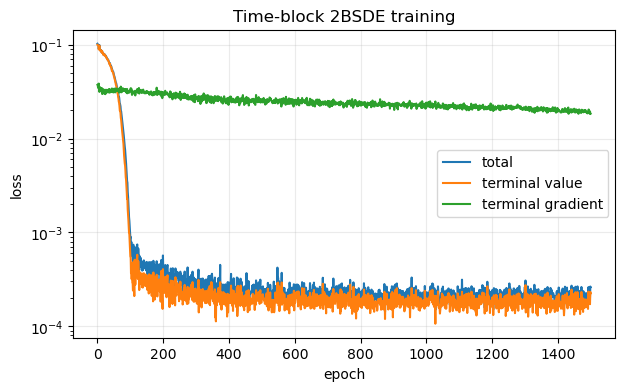

In [8]:
plt.figure(figsize=(7, 4))
plt.semilogy(history.total_loss, label="total")
plt.semilogy(history.terminal_value_loss, label="terminal value")
plt.semilogy(history.terminal_gradient_loss, label="terminal gradient")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("Time-block 2BSDE training")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


## Compare the learned initial value with the analytic solution


In [9]:
with torch.no_grad():
    V0_learned = model.value(0.0, S0)

print("VALUE")
print(" learned:", V0_learned.item())
print(" exact:  ", V0_exact.item())
print(" abs err:", abs(V0_learned.item() - V0_exact.item()))


VALUE
 learned: 0.31497388145888516
 exact:   0.3125
 abs err: 0.002473881458885163


## Test the inner Hamiltonian optimizer with the analytic control $u^*=1$

In [10]:
with torch.no_grad():
    state_batch = torch.tensor(
        [
            [0.0, 0.25, 0.50, 0.25],
            [0.2, 0.10, 0.20, 0.70],
            [-0.3, 0.65, 0.25, 0.10],
        ],
        dtype=DTYPE,
    )

    z_batch = torch.stack(
        [exact_gradient(s) for s in state_batch]
    )
    gamma_batch = torch.stack(
        [exact_hessian(s) for s in state_batch]
    )

    _, u_from_exact_derivatives = hamiltonian_optimizer.minimise(
        state_batch,
        z_batch,
        gamma_batch,
        time=None
    )

print("using exact derivatives:")
print(" numerical u* =", u_from_exact_derivatives[:, 0])
print(" analytic  u* =", torch.ones(len(state_batch), dtype=DTYPE))
print(
    " max abs error =",
    (u_from_exact_derivatives[:, 0] - 1.0).abs().max().item(),
)

using exact derivatives:
 numerical u* = tensor([1., 1., 1.], dtype=torch.float64)
 analytic  u* = tensor([1., 1., 1.], dtype=torch.float64)
 max abs error = 0.0


## Fresh-path 2BSDE evaluation

As in the original notebook, compare the Hamiltonian minimisers returned along the forward paths with the analytic control $u^*=1$.


In [11]:
result = evaluate_time_blocks(
    model,
    num_paths=500,
    evaluate_policy=False,
)

paths = result.paths

u_star_path = paths["u_star_path"][..., 0]
mean_u_by_time = u_star_path.mean(dim=0)
mae_u_by_time = (u_star_path - 1.0).abs().mean(dim=0)

print("mean learned u* over all paths/times =", u_star_path.mean().item())
print("mean absolute control error =", (u_star_path - 1.0).abs().mean().item())


mean learned u* over all paths/times = 0.9279844444444444
mean absolute control error = 0.07201555555555555


Mean Hessian error: 1.301174526813344


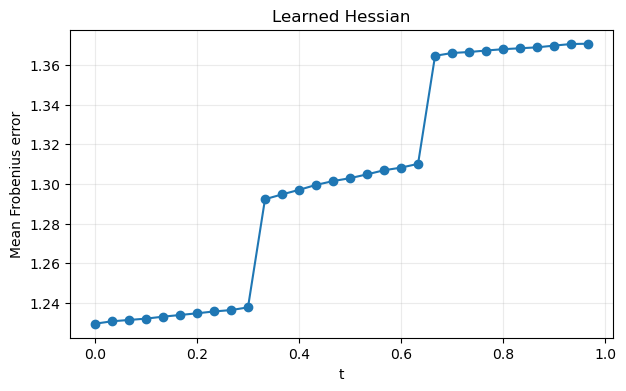

In [12]:
with torch.no_grad():
    # Gamma at step k corresponds to the state at the START of that step.
    Gamma_learned = paths["Gamma_path"]           # [paths, steps, 4, 4]
    Gamma_exact = exact_hessian(paths["S_path"][:, :-1])

    error = torch.linalg.matrix_norm(
        Gamma_learned - Gamma_exact, ord="fro", dim=(-2, -1)
    )                                           # [paths, steps]

print("Mean Hessian error:", error.mean().item())

plt.figure(figsize=(7, 4))
plt.plot(
    paths["time_path"][:-1].detach().cpu().numpy(),
    error.mean(dim=0).detach().cpu().numpy(),
    marker="o",
)
plt.xlabel("t")
plt.ylabel("Mean Frobenius error")
plt.title("Learned Hessian")
plt.grid(alpha=0.25)
plt.show()

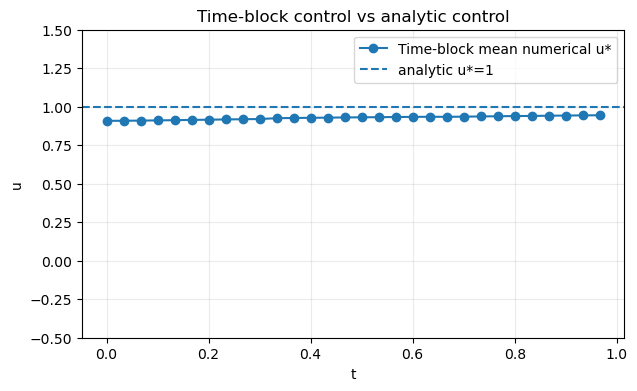

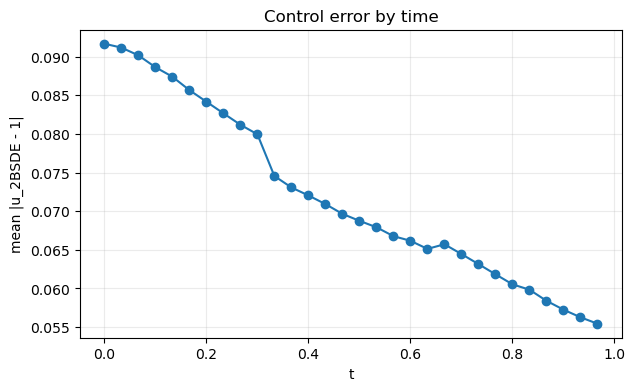

In [13]:
time_grid = torch.arange(
    config.num_time_steps,
    dtype=DTYPE,
) * config.dt

plt.figure(figsize=(7, 4))
plt.plot(
    time_grid.numpy(),
    mean_u_by_time.numpy(),
    marker="o",
    label="Time-block mean numerical u*",
)
plt.axhline(
    1.0,
    linestyle="--",
    label="analytic u*=1",
)
plt.xlabel("t")
plt.ylabel("u")
plt.ylim(-0.5, 1.5)
plt.title("Time-block control vs analytic control")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(
    time_grid.numpy(),
    mae_u_by_time.numpy(),
    marker="o",
)
plt.xlabel("t")
plt.ylabel("mean |u_2BSDE - 1|")
plt.title("Control error by time")
plt.grid(alpha=0.25)
plt.show()
